# ESS 배터리 Cycle Life 예측 - DAY 2 모델 개발 및 평가

## 목적
`02_feature_engineering.ipynb`에서 만든 초기 100사이클 피처로 `cycle_life`를 예측하는 회귀 모델을 개발합니다.

- **Train/CV**: Batch 1 Train 영역에서 충전정책 그룹 단위 교차검증
- **Valid**: Batch 1 Hold-out, 후보 모델과 피처 조합 비교
- **Test**: Batch 2, 모델과 설정을 확정한 뒤 마지막에 한 번 평가
- **주요 지표**: MAPE (%)
- **비교 Target**: Severson et al. (2019) 원논문 Test error 9.1%

> Batch 2 Test 결과를 확인한 후 피처·모델·하이퍼파라미터를 다시 선택하지 않습니다. Test 결과는 최종 일반화 성능과 실패 원인을 해석하는 데만 사용합니다.

## 0. 실행 환경과 라이브러리

결측값 대체와 표준화를 모델 Pipeline 내부에 넣어 각 Train fold에서만 학습되도록 합니다. Target은 오른쪽 꼬리가 긴 Cycle Life 분포를 완화하기 위해 `log(cycle_life)`로 학습하고, 예측 시 원래 Cycle 단위로 되돌립니다.

In [3]:
import ast
import json
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/da_mpl_cache')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, HuberRegressor, Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 학습 수렴·수치 관련 경고는 숨기지 않고 확인합니다.

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / 'output' / 'day2' / 'model_features.csv').exists())
DATA_PATH = ROOT / 'output' / 'day2' / 'model_features.csv'
MANIFEST_PATH = ROOT / 'output' / 'day2' / 'feature_manifest.csv'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 100)

print('프로젝트 폴더:', ROOT)
print('Python:', sys.executable)

프로젝트 폴더: /Users/jiyong/Desktop/DA
Python: /Users/jiyong/Desktop/DA/.venv311/bin/python


## 1. 모델링 데이터 불러오기

Feature Engineering 결과와 피처 명세를 불러옵니다. `batch`, `cell_id`, `policy`는 분할과 오류분석에만 사용하며 모델 입력 `X`에서는 제외합니다.

In [4]:
model_table = pd.read_csv(DATA_PATH)
feature_manifest = pd.read_csv(MANIFEST_PATH)
all_features = feature_manifest['feature'].tolist()

required_columns = {'batch', 'cell_id', 'policy', 'cycle_life', *all_features}
missing_columns = sorted(required_columns.difference(model_table.columns))
assert not missing_columns, f'필요한 열이 없습니다: {missing_columns}'
assert model_table['cell_id'].is_unique
assert model_table['cycle_life'].gt(0).all()

print(f'모델링 데이터: {model_table.shape[0]}셀 × {model_table.shape[1]}열')
display(model_table.groupby('batch', sort=False).agg(
    cells=('cell_id', 'size'),
    policies=('policy', 'nunique'),
    life_median=('cycle_life', 'median'),
    life_min=('cycle_life', 'min'),
    life_max=('cycle_life', 'max'),
))
display(feature_manifest)

모델링 데이터: 85셀 × 19열


,cells,policies,life_median,life_min,life_max
batch,,,,,
Batch 1,46,23,858.5,534.0,1227.0
Batch 2,39,12,472.0,392.0,1186.0


,feature,group,available_by_cycle,selection_reason
0,dq_log_var,delta_q_core,100,DAY 1에서 Cycle Life와 강하고 Batch별 방향이 일관된 ΔQ(V) 신호
1,dq_min,delta_q_core,100,DAY 1에서 Cycle Life와 강하고 Batch별 방향이 일관된 ΔQ(V) 신호
2,qd_10,capacity,100,초기 방전용량 수준과 Cycle 10~100의 감소 추세
3,qd_100,capacity,100,초기 방전용량 수준과 Cycle 10~100의 감소 추세
4,qd_delta_100_10,capacity,100,초기 방전용량 수준과 Cycle 10~100의 감소 추세
5,qd_slope_10_100,capacity,100,초기 방전용량 수준과 Cycle 10~100의 감소 추세
6,ir_10,resistance,100,초기 내부저항 수준과 변화량
7,ir_100,resistance,100,초기 내부저항 수준과 변화량
8,ir_delta_100_10,resistance,100,초기 내부저항 수준과 변화량
9,mean_tavg_100,temperature,100,초기 100사이클의 열적 운전 조건


## 2. Batch 1 개발 데이터와 Batch 2 Test 격리

Batch 2는 최종 Test이므로 우선 별도 객체에 격리합니다. 이후 후보 피처·모델 비교와 하이퍼파라미터 조정에는 Batch 1만 사용합니다.

In [5]:
batch1 = model_table[model_table['batch'].eq('Batch 1')].copy().reset_index(drop=True)
batch2_test = model_table[model_table['batch'].eq('Batch 2')].copy().reset_index(drop=True)

assert len(batch1) == 46
assert len(batch2_test) == 39
assert set(batch1['cell_id']).isdisjoint(batch2_test['cell_id'])

print('Batch 1 개발 데이터:', len(batch1), '셀')
print('Batch 2 최종 Test:', len(batch2_test), '셀 - 최종 모델 확정 전까지 정답 평가 금지')

Batch 1 개발 데이터: 46 셀
Batch 2 최종 Test: 39 셀 - 최종 모델 확정 전까지 정답 평가 금지


## 3. Batch 1 Train·Valid 분리

같은 충전정책의 셀은 측정조건이 매우 유사합니다. 동일 정책이 Train과 Valid 양쪽에 섞이면 모델이 정책 특성을 미리 본 상태가 될 수 있으므로 `policy`를 그룹으로 사용해 Hold-out을 만듭니다.

- Train: 후보 모델 학습과 Group CV 하이퍼파라미터 조정
- Valid: 모델·피처 조합 선택과 과적합 확인
- Test: 이 단계에서는 사용하지 않음

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, valid_idx = next(splitter.split(batch1, groups=batch1['policy']))
train_df = batch1.iloc[train_idx].copy()
valid_df = batch1.iloc[valid_idx].copy()

overlap = set(train_df['policy']).intersection(valid_df['policy'])
assert not overlap, f'Train·Valid 정책 중복: {overlap}'

split_summary = pd.DataFrame({
    '구분': ['Train', 'Valid', 'Test'],
    'Batch': ['Batch 1', 'Batch 1', 'Batch 2'],
    '셀 수': [len(train_df), len(valid_df), len(batch2_test)],
    '정책 수': [train_df.policy.nunique(), valid_df.policy.nunique(), batch2_test.policy.nunique()],
    'Cycle Life 중앙값': [train_df.cycle_life.median(), valid_df.cycle_life.median(), batch2_test.cycle_life.median()],
})
display(split_summary)
print('Train·Valid 중복 정책:', len(overlap), '개')

,구분,Batch,셀 수,정책 수,Cycle Life 중앙값
0,Train,Batch 1,33,17,857.0
1,Valid,Batch 1,13,6,860.0
2,Test,Batch 2,39,12,472.0


Train·Valid 중복 정책: 0 개


## 4. 비교할 피처 조합

보조 피처의 추가 효과를 확인하기 위해 피처 집합을 단계적으로 비교합니다.

1. `dq_log_var_only`: 원논문과 DAY 1에서 가장 강했던 단일 ΔQ 피처
2. `dq_core`: 강한 ΔQ 후보 두 개를 함께 사용하되 중복 효과 확인
3. `core_plus_health`: ΔQ에 QD·IR·온도·충전시간의 대표 변화 피처 추가
4. `all_candidates`: 충전정책까지 포함한 전체 후보

`dq_log_var`와 `dq_min`은 서로 매우 강하게 연관되므로, 둘을 같이 넣는 것이 단일 피처보다 실제로 좋은지는 CV·Valid 결과로 판단합니다.

In [7]:
feature_sets = {
    'dq_log_var_only': ['dq_log_var'],
    'dq_core': ['dq_log_var', 'dq_min'],
    'core_plus_health': [
        'dq_log_var', 'qd_slope_10_100', 'ir_delta_100_10',
        'mean_tavg_100', 'mean_chargetime_100'
    ],
    'all_candidates': all_features,
}

for name, features in feature_sets.items():
    assert set(features).issubset(all_features)
    print(f'{name:20s}: {len(features):2d}개 - {features}')

dq_log_var_only     :  1개 - ['dq_log_var']
dq_core             :  2개 - ['dq_log_var', 'dq_min']
core_plus_health    :  5개 - ['dq_log_var', 'qd_slope_10_100', 'ir_delta_100_10', 'mean_tavg_100', 'mean_chargetime_100']
all_candidates      : 15개 - ['dq_log_var', 'dq_min', 'qd_10', 'qd_100', 'qd_delta_100_10', 'qd_slope_10_100', 'ir_10', 'ir_100', 'ir_delta_100_10', 'mean_tavg_100', 'mean_tmax_100', 'mean_chargetime_100', 'policy_first_c_rate', 'policy_switch_soc', 'policy_second_c_rate']


## 5. 평가 지표와 Pipeline 정의

### MAPE
실제 수명 대비 오차의 비율을 평균한 값입니다. 수명이 서로 다른 셀을 상대오차 기준으로 비교할 수 있어 과제와 원논문의 주지표로 사용합니다.

### Pipeline
각 CV fold의 Train 데이터에서만 다음 순서로 학습합니다.

1. 결측값을 Train 중앙값으로 대체
2. 피처를 표준화
3. 회귀 모델 학습
4. `log(cycle_life)` 예측을 원래 Cycle 단위로 복원

이 구조는 전체 데이터의 중앙값·평균이 미리 Valid·Test에 전달되는 전처리 누수를 방지합니다.

In [8]:
def mape_percent(y_true, y_pred):
    return mean_absolute_percentage_error(y_true, y_pred) * 100

def make_regressor(model):
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', model),
    ])
    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log,
        inverse_func=np.exp,
        check_inverse=False,
    )

model_specs = {
    'Ridge': {
        'estimator': make_regressor(Ridge()),
        'params': {'regressor__model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]},
    },
    'ElasticNet': {
        'estimator': make_regressor(ElasticNet(max_iter=20000, random_state=42)),
        'params': {
            'regressor__model__alpha': [0.0001, 0.001, 0.01, 0.1],
            'regressor__model__l1_ratio': [0.1, 0.5, 0.9],
        },
    },
    'Huber': {
        'estimator': make_regressor(HuberRegressor(max_iter=5000)),
        'params': {
            'regressor__model__epsilon': [1.1, 1.35, 1.7],
            'regressor__model__alpha': [0.0001, 0.001, 0.01],
        },
    },
    'GradientBoosting': {
        'estimator': make_regressor(GradientBoostingRegressor(random_state=42, loss='huber')),
        'params': {
            'regressor__model__n_estimators': [50, 100],
            'regressor__model__learning_rate': [0.03, 0.1],
            'regressor__model__max_depth': [1, 2],
            'regressor__model__min_samples_leaf': [2, 4],
        },
    },
}

print('후보 모델:', list(model_specs))

후보 모델: ['Ridge', 'ElasticNet', 'Huber', 'GradientBoosting']


## 6. 중앙값 기준 모델(Baseline)

머신러닝 모델이 의미 있으려면 모든 셀을 Train 중앙값으로 예측하는 단순 기준보다 좋아야 합니다. Baseline은 복잡한 모델의 성능을 판단할 최소 기준입니다.

In [9]:

baseline_cv = GroupKFold(n_splits=5)
baseline_cv_scores = -cross_val_score(
    DummyRegressor(strategy='median'),
    np.zeros((len(train_df), 1)),
    train_df['cycle_life'],
    groups=train_df['policy'],
    cv=baseline_cv,
    scoring='neg_mean_absolute_percentage_error',
) * 100

baseline = DummyRegressor(strategy='median')
baseline.fit(np.zeros((len(train_df), 1)), train_df['cycle_life'])
baseline_valid_pred = baseline.predict(np.zeros((len(valid_df), 1)))
baseline_cv_mape = baseline_cv_scores.mean()
baseline_valid_mape = mape_percent(valid_df['cycle_life'], baseline_valid_pred)

baseline_result = {
    'feature_set': 'none',
    'model': 'MedianBaseline',
    'n_features': 0,
    'cv_mape': baseline_cv_mape,
    'valid_mape': baseline_valid_mape,
    'gap_train_valid': baseline_valid_mape - baseline_cv_mape,
    'best_params': '{}',
}
display(pd.DataFrame([baseline_result]).round(3))

,feature_set,model,n_features,cv_mape,valid_mape,gap_train_valid,best_params
0,none,MedianBaseline,0,22.958,14.203,-8.755,{}


## 7. 피처 조합 × 후보 모델 비교 및 하이퍼파라미터 조정

Train 내부에서 동일 충전정책을 같은 fold에 유지하는 `GroupKFold`를 사용합니다. 각 피처 조합과 모델에 대해 Grid Search로 하이퍼파라미터를 조정하고, CV MAPE와 별도 Valid MAPE를 기록합니다.

- 낮은 CV MAPE: Train 내부에서 안정적인 예측
- 낮은 Valid MAPE: 보지 못한 충전정책 셀에 대한 일반화
- 큰 양의 Train–Valid Gap: 과적합 또는 정책 일반화 저하 의심

In [10]:
group_cv = GroupKFold(n_splits=5)
candidate_rows = [baseline_result]
fitted_searches = {}

for feature_set_name, features in feature_sets.items():
    X_train = train_df[features]
    y_train = train_df['cycle_life']
    X_valid = valid_df[features]
    y_valid = valid_df['cycle_life']

    for model_name, spec in model_specs.items():
        search = GridSearchCV(
            estimator=spec['estimator'],
            param_grid=spec['params'],
            scoring='neg_mean_absolute_percentage_error',
            cv=group_cv,
            n_jobs=-1,
            refit=True,
            error_score='raise',
        )
        search.fit(X_train, y_train, groups=train_df['policy'])
        valid_pred = search.predict(X_valid)
        cv_mape = -search.best_score_ * 100
        valid_mape = mape_percent(y_valid, valid_pred)

        key = (feature_set_name, model_name)
        fitted_searches[key] = search
        candidate_rows.append({
            'feature_set': feature_set_name,
            'model': model_name,
            'n_features': len(features),
            'cv_mape': cv_mape,
            'valid_mape': valid_mape,
            'gap_train_valid': valid_mape - cv_mape,
            'best_params': json.dumps(search.best_params_, ensure_ascii=False),
        })

candidate_results = (
    pd.DataFrame(candidate_rows)
      .sort_values(['valid_mape', 'cv_mape'])
      .reset_index(drop=True)
)
display(candidate_results.round(3))

,feature_set,model,n_features,cv_mape,valid_mape,gap_train_valid,best_params
0,dq_log_var_only,GradientBoosting,1,8.890,5.885,-3.005,"{""regressor__model__learning_rate"": 0.1, ""regr..."
1,dq_core,GradientBoosting,2,8.967,6.063,-2.904,"{""regressor__model__learning_rate"": 0.1, ""regr..."
2,core_plus_health,GradientBoosting,5,9.121,7.325,-1.795,"{""regressor__model__learning_rate"": 0.1, ""regr..."
3,all_candidates,GradientBoosting,15,8.525,7.847,-0.678,"{""regressor__model__learning_rate"": 0.1, ""regr..."
4,dq_core,ElasticNet,2,7.341,10.917,3.576,"{""regressor__model__alpha"": 0.1, ""regressor__m..."
5,dq_core,Ridge,2,7.265,12.726,5.461,"{""regressor__model__alpha"": 1.0}"
6,all_candidates,ElasticNet,15,6.954,13.406,6.452,"{""regressor__model__alpha"": 0.01, ""regressor__..."
7,dq_core,Huber,2,8.430,13.717,5.287,"{""regressor__model__alpha"": 0.01, ""regressor__..."
8,all_candidates,Ridge,15,7.826,14.138,6.312,"{""regressor__model__alpha"": 1.0}"
9,none,MedianBaseline,0,22.958,14.203,-8.755,{}


## 8. 최종 모델 선택

Baseline을 제외한 후보 중 최저 Valid MAPE에서 1%p 이내인 조합을 추립니다. 그중 피처 수가 적은 조합을 우선하고, 동률이면 Valid−CV Gap, CV MAPE 순서로 오름차순 정렬하여 선택합니다. 1%p는 이번 실험에서 정한 단순성 우선 허용폭이며 통계적 유의성 기준은 아닙니다. Gap이 음수라고 더 안정적인 모델임을 보장하지 않으므로 출력 결과와 표본 수의 한계를 함께 해석합니다.

> 이 시점까지 Batch 2 Test MAPE는 계산하지 않습니다.

In [11]:
eligible = candidate_results[candidate_results['model'].ne('MedianBaseline')].copy()
best_valid = eligible['valid_mape'].min()
near_best = eligible[eligible['valid_mape'] <= best_valid + 1.0].copy()
selected_row = near_best.sort_values(
    ['n_features', 'gap_train_valid', 'cv_mape'],
    ascending=[True, True, True],
).iloc[0]

selected_feature_set = selected_row['feature_set']
selected_model_name = selected_row['model']
selected_features = feature_sets[selected_feature_set]
selected_search = fitted_searches[(selected_feature_set, selected_model_name)]

print('선택 피처 조합:', selected_feature_set)
print('선택 모델:', selected_model_name)
print('피처:', selected_features)
print('Train CV MAPE:', round(selected_row['cv_mape'], 3), '%')
print('Valid MAPE:', round(selected_row['valid_mape'], 3), '%')
print('Train–Valid Gap:', round(selected_row['gap_train_valid'], 3), '%p')
print('최적 하이퍼파라미터:', selected_search.best_params_)

선택 피처 조합: dq_log_var_only
선택 모델: GradientBoosting
피처: ['dq_log_var']
Train CV MAPE: 8.89 %
Valid MAPE: 5.885 %
Train–Valid Gap: -3.005 %p
최적 하이퍼파라미터: {'regressor__model__learning_rate': 0.1, 'regressor__model__max_depth': 1, 'regressor__model__min_samples_leaf': 2, 'regressor__model__n_estimators': 100}


### 선택 결과 해석

- 최종 선택은 `dq_log_var` 한 개를 사용한 Gradient Boosting이었습니다. 하이퍼파라미터는 `n_estimators=100`, `learning_rate=0.1`, `max_depth=1`, `min_samples_leaf=2`였습니다. 깊이가 1인 얕은 트리를 사용하므로 소표본에서 복잡도를 제한한 결과입니다.
- 중앙값 Baseline은 Train Group CV MAPE `22.958%`, Valid MAPE `14.203%`였지만 선택 모델은 각각 `8.890%`, `5.885%`로 개선되었습니다. 단순 중앙값 예측보다 초기 ΔQ 신호가 Batch 1 내부 수명 예측에 유효했습니다.
- `dq_log_var`에 `dq_min`을 추가한 Gradient Boosting의 Valid MAPE는 `6.063%`로 단일 피처보다 소폭 나빴습니다. 두 ΔQ 피처의 강한 중복 때문에 추가 이득이 없었던 것으로 판단했습니다.
- 건강상태 보조 피처 5개 모델은 Valid MAPE `7.325%`, 전체 15개 피처 모델은 `7.847%`였습니다. 보조 피처를 늘려도 Batch 1 Hold-out 성능이 개선되지 않았으므로 가장 단순한 단일 ΔQ 모델을 선택했습니다.
- ElasticNet의 가장 좋은 Valid 결과는 `dq_core` 조합의 `10.917%`였습니다. 원논문과 직접 연결되는 해석 가능한 모델이지만, 이번 정책 그룹 Hold-out에서는 Gradient Boosting보다 오차가 컸습니다.
- 선택 모델의 Train−Valid Gap은 `-3.005%p`로 Valid 오차가 CV 평균보다 오히려 낮았습니다. 따라서 이 Hold-out에서 뚜렷한 과적합 징후는 없지만, Valid가 13셀뿐이므로 분할에 따른 변동성이 클 수 있습니다.

## 9. 모델과 설정 고정 후 Batch 2 최종 Test

피처·모델·하이퍼파라미터 선택이 끝났으므로 선택한 설정을 고정합니다. 그 후 Batch 1 전체 46셀로 다시 학습하고 Batch 2를 한 번 예측합니다.

이 셀 실행 이후 Test 결과를 이유로 모델을 다시 고르면 Batch 2는 더 이상 공정한 Test가 아닙니다.

In [12]:
final_model = clone(selected_search.best_estimator_)
final_model.fit(batch1[selected_features], batch1['cycle_life'])

test_pred = final_model.predict(batch2_test[selected_features])
test_mape = mape_percent(batch2_test['cycle_life'], test_pred)
test_mae = mean_absolute_error(batch2_test['cycle_life'], test_pred)
test_rmse = np.sqrt(mean_squared_error(batch2_test['cycle_life'], test_pred))

print('Batch 2 Test MAPE:', round(test_mape, 3), '%')
print('Batch 2 Test MAE:', round(test_mae, 1), 'cycles')
print('Batch 2 Test RMSE:', round(test_rmse, 1), 'cycles')
print('원논문 9.1% 대비 Gap:', round(test_mape - 9.1, 3), '%p')

Batch 2 Test MAPE: 30.437 %
Batch 2 Test MAE: 151.7 cycles
Batch 2 Test RMSE: 169.7 cycles
원논문 9.1% 대비 Gap: 21.337 %p


## 10. 지정 성능표

Gap은 뒤 단계의 MAPE에서 앞 단계의 MAPE를 뺀 값입니다. 양수이면 뒤 단계에서 오차가 증가했다는 의미입니다.

- Train−Valid 표기 항목: `Valid MAPE - Train CV MAPE`
- Valid−Test 표기 항목: `Test MAPE - Valid MAPE`
- Target−Test 표기 항목: `Test MAPE - 원논문 9.1%`

In [13]:
cv_mape = float(selected_row['cv_mape'])
valid_mape = float(selected_row['valid_mape'])

performance_report = pd.DataFrame([
    {'구분': 'Train (Batch 1 CV)', 'MAPE (%)': cv_mape, '비고': '정책 그룹 5-Fold CV'},
    {'구분': 'Valid (Batch 1 Hold-out)', 'MAPE (%)': valid_mape, '비고': 'Train과 충전정책 중복 없음'},
    {'구분': 'Test (Batch 2)', 'MAPE (%)': test_mape, '비고': '최종 모델 확정 후 1회 평가'},
    {'구분': 'Gap (Train-Valid)', 'MAPE (%)': valid_mape - cv_mape, '비고': '(+) 과적합·정책 일반화 저하 의심'},
    {'구분': 'Gap (Valid-Test)', 'MAPE (%)': test_mape - valid_mape, '비고': '(+) Batch 간 일반화 저하 의심'},
    {'구분': 'Gap (Target-Test)', 'MAPE (%)': test_mape - 9.1, '비고': 'Target: 원논문 9.1%'},
])
display(performance_report.round(3))

,구분,MAPE (%),비고
0,Train (Batch 1 CV),8.890,정책 그룹 5-Fold CV
1,Valid (Batch 1 Hold-out),5.885,Train과 충전정책 중복 없음
2,Test (Batch 2),30.437,최종 모델 확정 후 1회 평가
3,Gap (Train-Valid),-3.005,(+) 과적합·정책 일반화 저하 의심
4,Gap (Valid-Test),24.552,(+) Batch 간 일반화 저하 의심
5,Gap (Target-Test),21.337,Target: 원논문 9.1%


## 11. 예측 결과와 큰 오차 셀 분석

MAPE 하나만으로는 모델이 어떤 셀에서 실패했는지 알 수 없습니다. 셀별 실제·예측 수명과 절대백분율오차(APE)를 계산하고, 해당 셀의 피처가 Batch 1 학습 범위를 벗어났는지 확인합니다.

- `outside_train_range_n`: 선택 피처 중 Batch 1 최솟값~최댓값 밖에 있는 피처 개수
- `missing_feature_n`: 원본 입력에서 결측인 선택 피처 개수

큰 오차 셀에서 이 값들이 높다면 Batch shift 또는 미측정값이 오차와 연관됐을 가능성이 있습니다.

In [14]:
test_predictions = batch2_test[['batch', 'cell_id', 'policy', 'cycle_life']].copy()
test_predictions['predicted_cycle_life'] = test_pred
test_predictions['residual_cycles'] = test_predictions['predicted_cycle_life'] - test_predictions['cycle_life']
test_predictions['absolute_error_cycles'] = test_predictions['residual_cycles'].abs()
test_predictions['ape_pct'] = (
    test_predictions['absolute_error_cycles'] / test_predictions['cycle_life'] * 100
)

train_min = batch1[selected_features].min()
train_max = batch1[selected_features].max()
outside_mask = batch2_test[selected_features].lt(train_min) | batch2_test[selected_features].gt(train_max)
test_predictions['outside_train_range_n'] = outside_mask.sum(axis=1).to_numpy()
test_predictions['missing_feature_n'] = batch2_test[selected_features].isna().sum(axis=1).to_numpy()

largest_errors = test_predictions.nlargest(10, 'ape_pct')
display(largest_errors.round({
    'predicted_cycle_life': 1, 'residual_cycles': 1,
    'absolute_error_cycles': 1, 'ape_pct': 2
}))

,batch,cell_id,policy,cycle_life,predicted_cycle_life,residual_cycles,absolute_error_cycles,ape_pct,outside_train_range_n,missing_feature_n
6,Batch 2,Batch2_C07,3.6C(9%)-5C,393.0,629.7,236.7,236.7,60.23,0,0
15,Batch 2,Batch2_C16,3.6C(9%)-5C,396.0,629.7,233.7,233.7,59.02,0,0
18,Batch 2,Batch2_C19,5.2C(50%)-4.25C,449.0,702.7,253.7,253.7,56.49,0,0
9,Batch 2,Batch2_C10,5.6C(26%)-4.5C-newstructure,791.0,1178.6,387.6,387.6,49.00,0,0
2,Batch 2,Batch2_C03,5.2C(50%)-4.25C,424.0,622.8,198.8,198.8,46.89,0,0
19,Batch 2,Batch2_C20,6C(60%)-3C,392.0,561.2,169.2,169.2,43.17,1,0
26,Batch 2,Batch2_C29,4.8C(80%)-4.8C,437.0,614.1,177.1,177.1,40.53,0,0
11,Batch 2,Batch2_C12,5.2C(50%)-4.25C,449.0,629.7,180.7,180.7,40.25,0,0
36,Batch 2,Batch2_C45,5.2C(58%)-4C-newstructure,841.0,1178.6,337.6,337.6,40.14,0,0
27,Batch 2,Batch2_C30,5.2C(58%)-4C,452.0,629.7,177.7,177.7,39.31,0,0


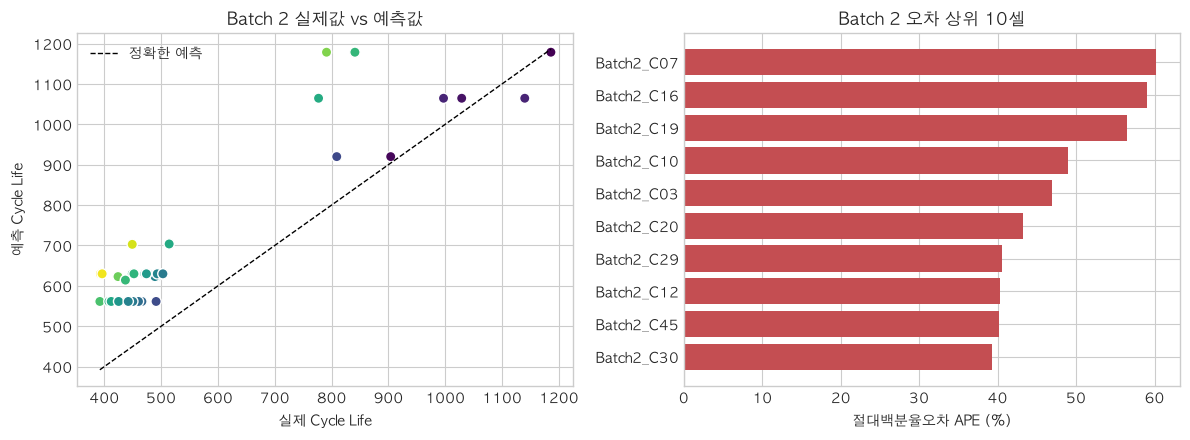

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(
    test_predictions['cycle_life'],
    test_predictions['predicted_cycle_life'],
    c=test_predictions['ape_pct'], cmap='viridis', s=55, edgecolor='white'
)
limits = [
    min(test_predictions['cycle_life'].min(), test_predictions['predicted_cycle_life'].min()),
    max(test_predictions['cycle_life'].max(), test_predictions['predicted_cycle_life'].max()),
]
axes[0].plot(limits, limits, '--', color='black', linewidth=1, label='정확한 예측')
axes[0].set(xlabel='실제 Cycle Life', ylabel='예측 Cycle Life', title='Batch 2 실제값 vs 예측값')
axes[0].legend(frameon=False)

top_plot = largest_errors.sort_values('ape_pct')
axes[1].barh(top_plot['cell_id'], top_plot['ape_pct'], color='#c44e52')
axes[1].set(xlabel='절대백분율오차 APE (%)', title='Batch 2 오차 상위 10셀')

plt.tight_layout()
plt.show()

## 12. 모델이 의존한 피처와 Batch shift 연결

선형모델은 표준화 회귀계수의 절댓값, 트리모델은 내장 Feature Importance로 상대적 영향력을 확인합니다. 여기에 Batch 1·2 중앙값 차이를 Batch 1 IQR로 나눈 값을 결합합니다.

중요도가 높으면서 Batch shift도 큰 피처는 Valid−Test 성능 차이에 영향을 줬을 가능성이 있습니다. 단, 이는 인과관계 확정이 아니라 오류 원인 가설입니다.

In [15]:
fitted_inner_model = final_model.regressor_.named_steps['model']
if hasattr(fitted_inner_model, 'coef_'):
    raw_importance = np.abs(np.ravel(fitted_inner_model.coef_))
    importance_type = '절대 표준화 계수'
elif hasattr(fitted_inner_model, 'feature_importances_'):
    raw_importance = fitted_inner_model.feature_importances_
    importance_type = 'Tree feature importance'
else:
    raw_importance = np.full(len(selected_features), np.nan)
    importance_type = '제공되지 않음'

feature_diagnostics = pd.DataFrame({
    'feature': selected_features,
    'importance': raw_importance,
})

b1_median = batch1[selected_features].median()
b2_median = batch2_test[selected_features].median()
b1_iqr = batch1[selected_features].quantile(0.75) - batch1[selected_features].quantile(0.25)
median_shift_iqr = ((b2_median - b1_median) / b1_iqr.replace(0, np.nan)).abs()
outside_rate = outside_mask.mean() * 100

feature_diagnostics['batch_median_shift_iqr'] = feature_diagnostics['feature'].map(median_shift_iqr)
feature_diagnostics['batch2_outside_train_range_pct'] = feature_diagnostics['feature'].map(outside_rate)
feature_diagnostics = feature_diagnostics.sort_values('importance', ascending=False)

print('중요도 종류:', importance_type)
display(feature_diagnostics.round(3))

중요도 종류: Tree feature importance


,feature,importance,batch_median_shift_iqr,batch2_outside_train_range_pct
0,dq_log_var,1.0,0.945,28.205


### 오류 분석 결과

- Batch 2의 39셀 중 37셀에서 예측값이 실제값보다 높았습니다. 실제 Cycle Life 중앙값은 `472`, 예측 중앙값은 약 `630`이었고 평균 잔차도 약 `+147사이클`이어서 모델이 Batch 2 수명을 전반적으로 과대예측했습니다.
- 실제 수명 500사이클 미만인 28셀의 MAPE는 약 `34.50%`, 평균 잔차는 `+152.63사이클`이었습니다. 반면 1,000사이클 이상 3셀의 MAPE는 약 `3.57%`였습니다. 즉 Batch 1보다 훨씬 많은 Batch 2 단수명 셀을 충분히 구분하지 못한 것이 전체 Test 오차의 핵심 패턴입니다.
- 가장 큰 오차는 Batch2_C07과 C16으로 실제 수명은 각각 393·396사이클이지만 약 630사이클로 예측해 APE가 약 `60.23%`, `59.02%`였습니다. 두 셀 모두 `3.6C(9%)-5C` 정책이어서 특정 단수명 정책에서 오차가 반복되었습니다.
- 선택 모델은 `dq_log_var` 하나만 사용하므로 IR 결측은 이번 최종 예측에 직접 영향을 주지 않았습니다. 학습범위 밖 `dq_log_var`를 가진 셀의 평균 MAPE(`28.95%`)가 범위 안 셀(`31.02%`)보다 더 높지는 않았으므로 단순한 범위 이탈만으로 실패를 설명할 수 없습니다.
- 그러나 `dq_log_var`의 Batch 1·2 중앙값 차이는 Batch 1 IQR의 약 `0.945배`였고 Batch 2의 `28.2%`가 Batch 1 최솟값~최댓값 범위 밖에 있었습니다. 또한 Gradient Boosting은 학습범위 밖으로 선형 외삽하기 어려우므로, ΔQ와 수명의 관계 자체가 Batch 2에서 달라진 분포 이동이 과대예측에 영향을 주었을 가능성이 있습니다.
- 위 결과는 `dq_log_var`가 실패의 단일 원인임을 증명하지 않습니다. Batch 1의 중앙 수명 `858.5`와 Batch 2의 `472`라는 Target 분포 차이, 충전정책 차이, 작은 학습 표본도 함께 영향을 주었을 가능성이 있습니다.

## 13. 결과 파일 저장

과제 성능 보고 형식에 따른 성능표, 전체 후보 비교 결과, Batch 2 셀별 예측 결과, 피처 중요도·분포 이동 진단을 `results/`에 저장합니다. GitHub README에서는 이 결과를 요약해 사용합니다.

In [16]:
performance_path = RESULTS_DIR / 'model_performance.csv'
candidate_path = RESULTS_DIR / 'candidate_model_results.csv'
prediction_path = RESULTS_DIR / 'batch2_test_predictions.csv'
diagnostics_path = RESULTS_DIR / 'feature_diagnostics.csv'
config_path = RESULTS_DIR / 'selected_model.json'

performance_report.to_csv(performance_path, index=False)
candidate_results.to_csv(candidate_path, index=False)
test_predictions.to_csv(prediction_path, index=False)
feature_diagnostics.to_csv(diagnostics_path, index=False)

selected_config = {
    'feature_set': selected_feature_set,
    'features': selected_features,
    'model': selected_model_name,
    'best_params': selected_search.best_params_,
    'target_transform': 'log / exp inverse',
    'selection_rule': 'within 1 percentage point of best Valid MAPE, prefer fewer features then smaller gap',
}
with open(config_path, 'w', encoding='utf-8') as file:
    json.dump(selected_config, file, ensure_ascii=False, indent=2)

for path in [performance_path, candidate_path, prediction_path, diagnostics_path, config_path]:
    print(path)

/Users/jiyong/Desktop/DA/results/model_performance.csv
/Users/jiyong/Desktop/DA/results/candidate_model_results.csv
/Users/jiyong/Desktop/DA/results/batch2_test_predictions.csv
/Users/jiyong/Desktop/DA/results/feature_diagnostics.csv
/Users/jiyong/Desktop/DA/results/selected_model.json


## 14. 최종 해석과 ESS 시사점

### 모델 선택 결과
DAY 1에서 가장 강하고 Batch별 방향이 일관됐던 `dq_log_var`를 단독 사용한 Gradient Boosting이 선택되었습니다. Train Group CV MAPE `8.890%`, Batch 1 Hold-out Valid MAPE `5.885%`로 중앙값 Baseline보다 크게 개선됐고, 보조 피처를 추가한 모델보다 단순하면서 Valid 오차가 낮았습니다. 이는 Batch 1 내부에서는 초기 ΔQ(V)의 분산이 Cycle Life 예측에 충분히 강한 신호였음을 보여줍니다.

### 성능 및 원논문 비교
확정 모델의 Batch 2 Test MAPE는 `30.437%`로, Valid보다 `24.552%p` 증가했고 원논문의 `9.1%`보다 `21.337%p` 높았습니다. 따라서 논문 성능을 재현하지 못했습니다. 이 결과는 Batch 1 내부 성능만으로 다른 Batch의 일반화를 보장할 수 없음을 보여줍니다. 원논문과의 차이에는 피처 구현 범위, 정책 그룹 분할, 작은 표본, Batch 간 데이터와 Target 분포 차이가 영향을 주었을 가능성이 있습니다.

### 오류와 한계
모델은 Batch 2의 39셀 중 37셀을 과대예측했고, 특히 500사이클 미만 단수명 셀에서 평균 MAPE가 `34.50%`였습니다. Batch 1에는 500사이클 미만 셀이 없지만 Batch 2에는 28셀이 있어, 학습 데이터가 Test의 단수명 영역을 충분히 포함하지 못했습니다. 핵심 피처 `dq_log_var`도 Batch 간 분포 차이를 보였습니다. 선택 모델이 단일 피처에 의존하고 Batch 1이 46셀에 불과하므로 분할 변동성과 구조적 분포 이동에 취약합니다.

### ESS 운영 시사점
초기 100사이클의 ΔQ(V)는 동일 Batch 안에서는 수명 선별에 유용했지만, 다른 Batch에 바로 적용하면 교체 시점을 과대평가할 위험이 확인됐습니다. 실제 ESS에서는 예측 Cycle Life만으로 교체를 결정하지 않고 BMS의 SOH·온도·내부저항·안전진단과 함께 점검 우선순위를 정해야 합니다. 실배포 전에는 제조 lot와 운전환경이 다양한 외부 데이터, Batch별 보정, 예측구간 또는 불확실성 경고, 주기적인 재학습이 필요합니다.

### 평가 설계의 한계

보고한 CV MAPE는 하이퍼파라미터 선택에도 사용된 값이므로 선택 편향이 있을 수 있습니다. 16개 후보를 작은 Valid 13셀로 비교했으므로 Valid 결과도 낙관적일 가능성이 있습니다. 독립 Batch 결과와 함께 해석하고 후속 연구에서는 반복 그룹 분할 또는 nested CV로 안정성을 확인해야 합니다. DAY 1에서 Batch 2를 이미 탐색했으므로 완전히 사전 미관찰된 Test라고 주장하지 않습니다. DAY 2의 모델·설정 선택에는 Batch 2 평가 결과를 사용하지 않았습니다.

### 최종 결론
이번 실험의 의미는 최고 성능 달성보다 EDA에서 발견한 ΔQ 신호를 실제 모델로 구현하고, 정책 그룹 검증과 독립 Batch Test를 통해 일반화 한계를 확인한 데 있습니다. Test 결과를 보고 모델을 다시 선택하지 않았으며, 낮은 Batch 2 성능 자체를 분포 이동과 학습 데이터 대표성의 시사점으로 해석했습니다.